Question 1

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import optimizers
from sklearn.model_selection import train_test_split

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 731s 4us/step


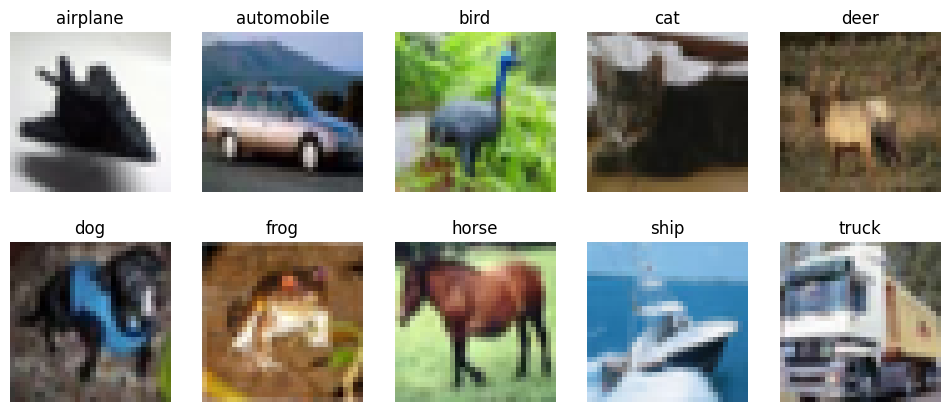

In [4]:
labels = y_train.ravel()

plt.figure(figsize=(12, 5))
for c in range(10):
    i = np.where(labels == c)[0][0]
    plt.subplot(2, 5, c + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[c])
    plt.axis('off')
plt.show()

In [5]:
X_all = x_train.reshape(-1, 3072) / 255.0
y_all = y_train.ravel()

X_tr, X_val, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.3, random_state=0)
print(X_tr.shape, X_val.shape)

(35000, 3072) (15000, 3072)


In [6]:
hidden_layers = [1, 2]
units_per_layer = [128, 256]
learning_rates = [0.001, 0.0001]

results = []
for hidden_layer in hidden_layers:
    for units in units_per_layer:
        for learning_rate in learning_rates:
            model = Sequential()
            model.add(Dense(units, activation='relu', input_shape=[3072]))
            for i in range(hidden_layer - 1):
                model.add(Dense(units, activation='relu'))
            model.add(Dense(10, activation='softmax'))
            model.compile(loss='sparse_categorical_crossentropy',
                          optimizer=optimizers.Adam(learning_rate=learning_rate), metrics=['accuracy'])
            h = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=10, batch_size=128, verbose=0)
            acc = h.history['val_accuracy'][-1]
            results.append([hidden_layer, units, learning_rate, acc])
            print(f'layers={hidden_layer}, units={units}, lr={learning_rate}: val accuracy = {acc:.4f}')

best_layers, best_units, best_lr, best_acc = max(results, key=lambda r: r[3])
print(f'\nBest: layers={best_layers}, units={best_units}, lr={best_lr}, val accuracy={best_acc:.4f}')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


layers=1, units=128, lr=0.001: val accuracy = 0.4456
layers=1, units=128, lr=0.0001: val accuracy = 0.4433
layers=1, units=256, lr=0.001: val accuracy = 0.4358
layers=1, units=256, lr=0.0001: val accuracy = 0.4545
layers=2, units=128, lr=0.001: val accuracy = 0.4740
layers=2, units=128, lr=0.0001: val accuracy = 0.4568
layers=2, units=256, lr=0.001: val accuracy = 0.4822
layers=2, units=256, lr=0.0001: val accuracy = 0.4755

Best: layers=2, units=256, lr=0.001, val accuracy=0.4822


In [7]:
model = Sequential()
model.add(Dense(best_units, activation='relu', input_shape=[3072]))
for i in range(best_layers - 1):
    model.add(Dense(best_units, activation='relu'))
model.add(Dense(10, activation='softmax'))
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=optimizers.Adam(learning_rate=best_lr), metrics=['accuracy'])

history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=20, batch_size=128)

Epoch 1/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.3024 - loss: 1.9271 - val_accuracy: 0.3441 - val_loss: 1.8092
Epoch 2/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.3803 - loss: 1.7230 - val_accuracy: 0.4017 - val_loss: 1.6750
Epoch 3/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.4157 - loss: 1.6368 - val_accuracy: 0.4287 - val_loss: 1.6071
Epoch 4/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.4375 - loss: 1.5848 - val_accuracy: 0.4229 - val_loss: 1.6292
Epoch 5/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.4536 - loss: 1.5400 - val_accuracy: 0.4345 - val_loss: 1.5983
Epoch 6/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.4687 - loss: 1.4967 - val_accuracy: 0.4596 - val_loss: 1.5107
Epoch 7/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.4758 - loss: 1.4701 - val_accuracy: 0.4545 - val_loss: 1.5470
Epoch 8/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.4879 - loss: 1.4464 - val_ac

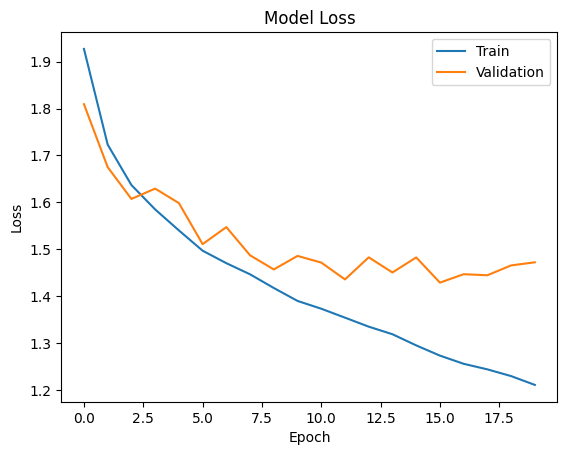

Final training loss: 1.2104403972625732
Final validation loss: 1.4719657897949219


In [8]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

print('Final training loss:', history.history['loss'][-1])
print('Final validation loss:', history.history['val_loss'][-1])

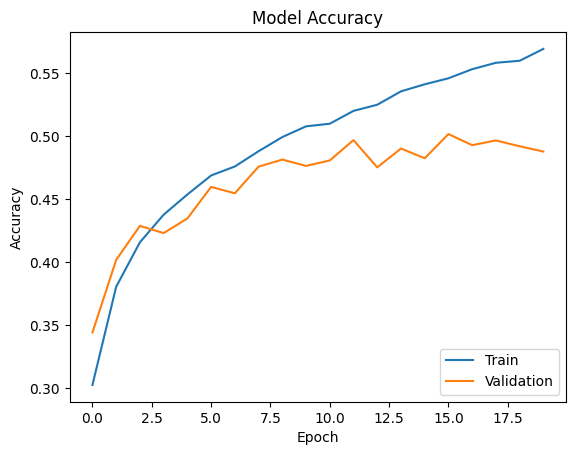

Final training accuracy: 0.5691142678260803
Final validation accuracy: 0.48766666650772095


In [9]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

print('Final training accuracy:', history.history['accuracy'][-1])
print('Final validation accuracy:', history.history['val_accuracy'][-1])

Question 2

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00291/airfoil_self_noise.dat'
cols = ['Frequency', 'Angle', 'Chord', 'Velocity', 'Thickness', 'SPL']
df = pd.read_csv(url, sep='\t', header=None, names=cols)

print(df.shape)
df.head()

(1503, 6)


,Frequency,Angle,Chord,Velocity,Thickness,SPL
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [15]:
df.describe()

,Frequency,Angle,Chord,Velocity,Thickness,SPL
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


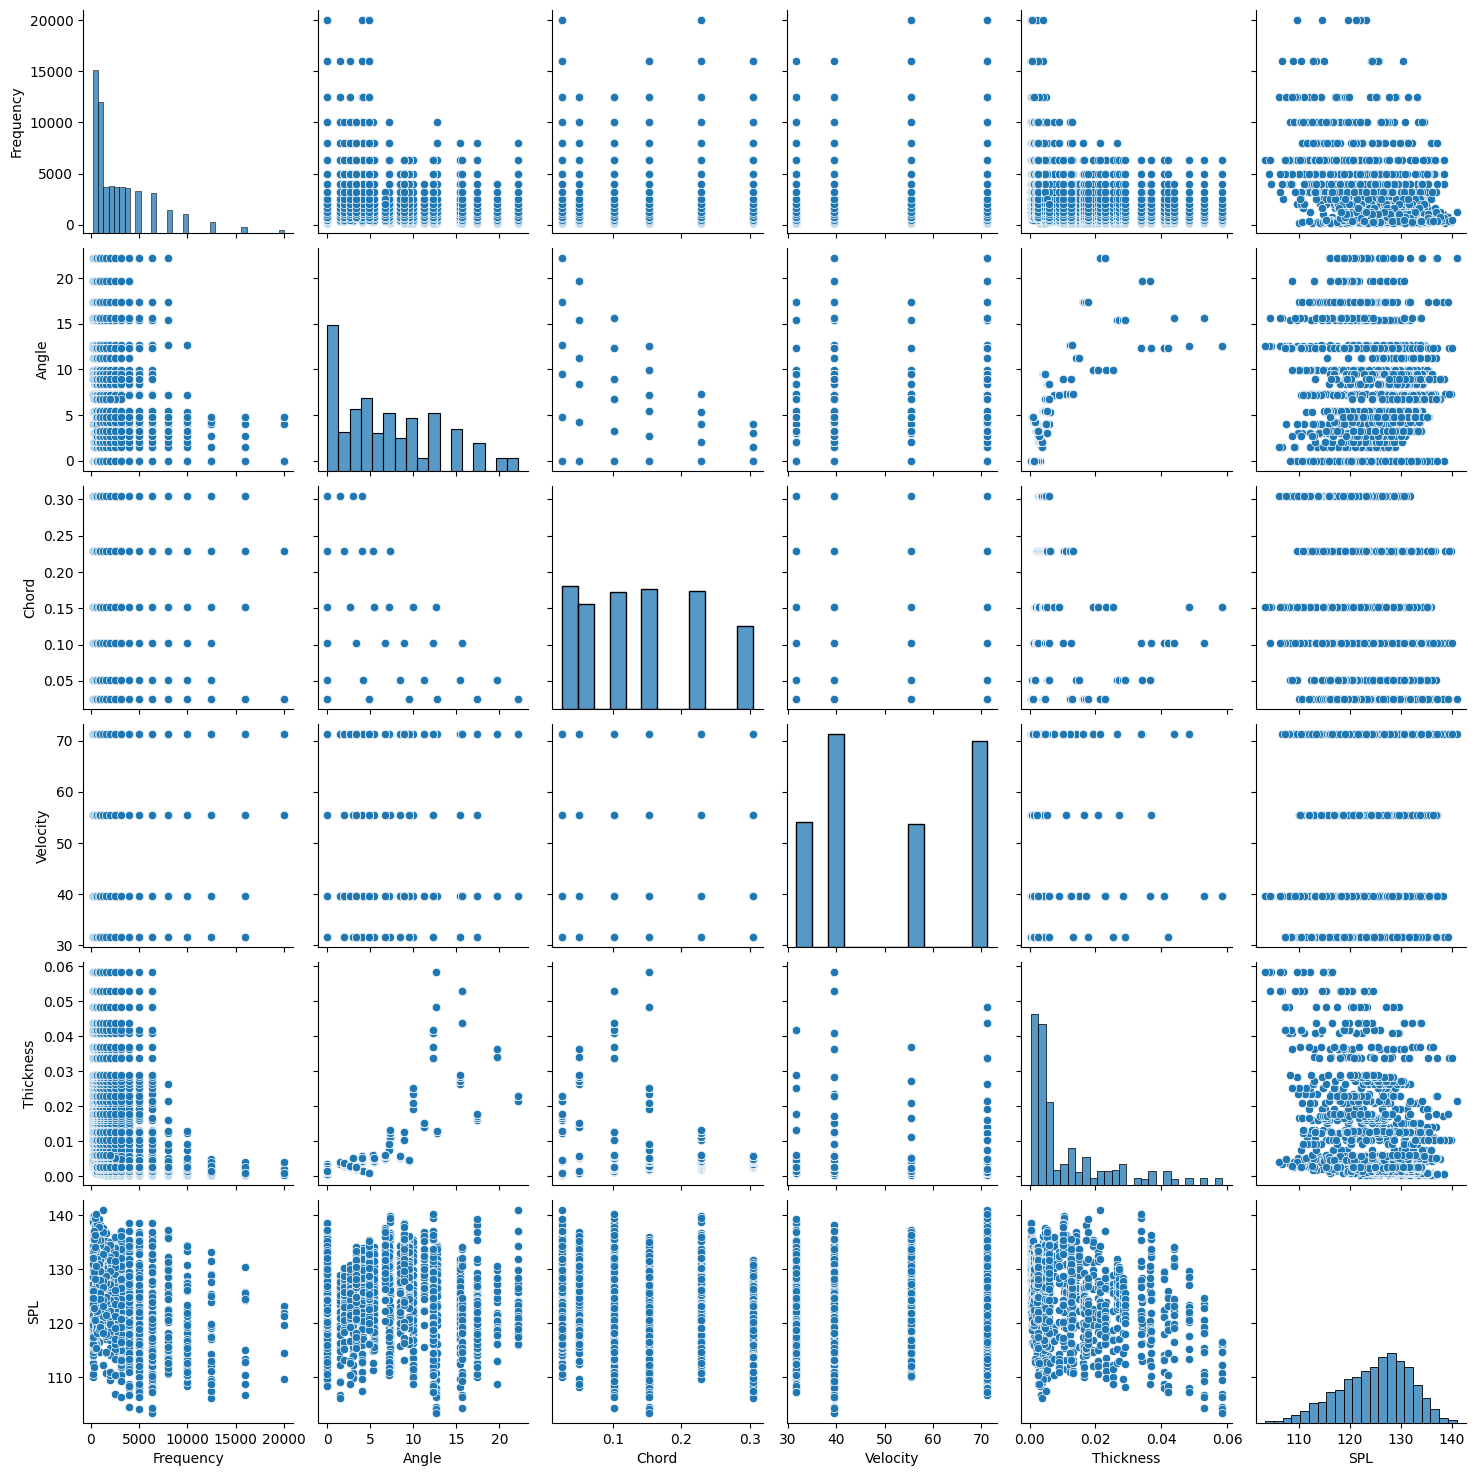

In [16]:
sns.pairplot(df)
plt.show()

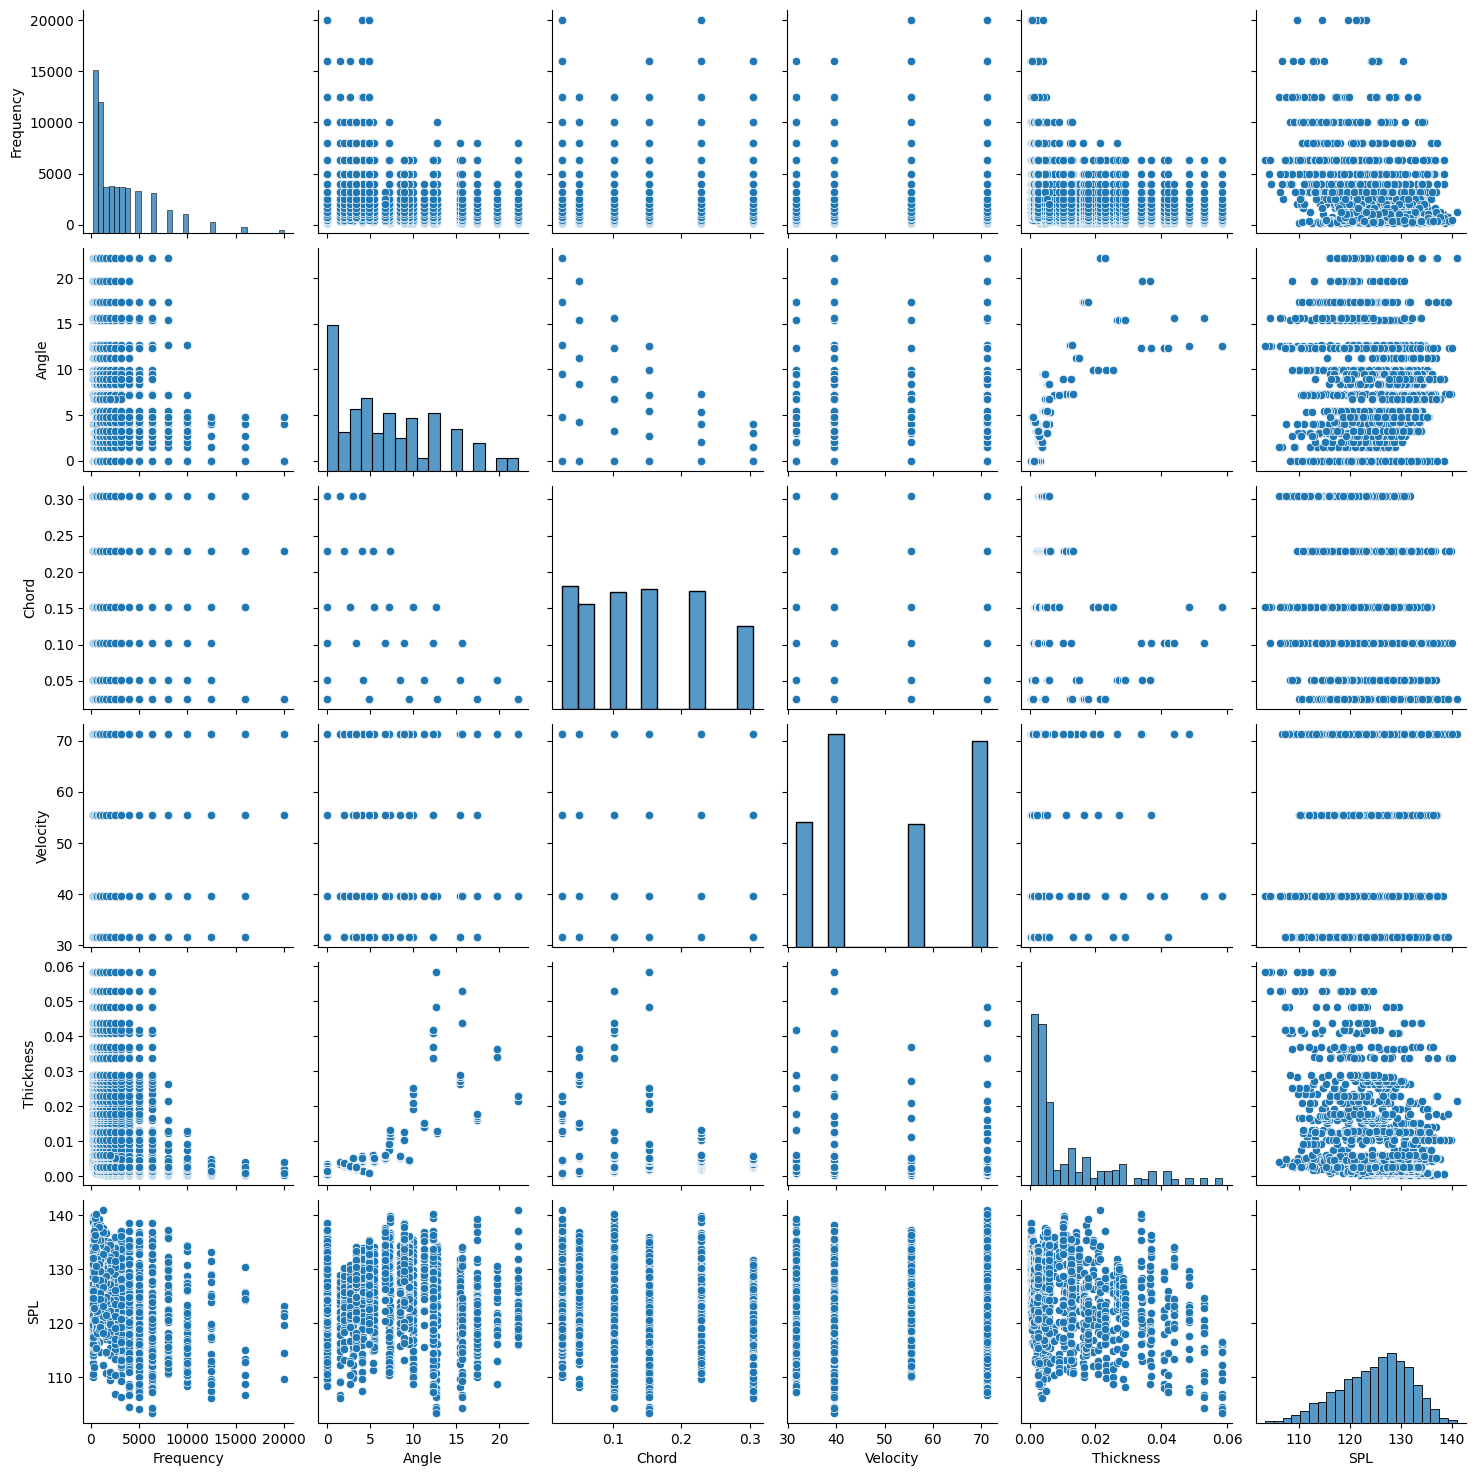

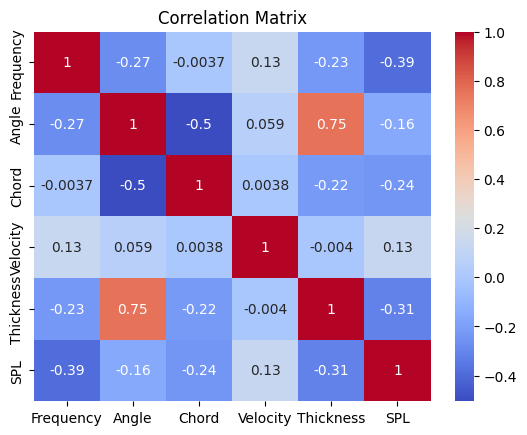

In [11]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [12]:
X = df.drop(columns='SPL').values
y = df['SPL'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


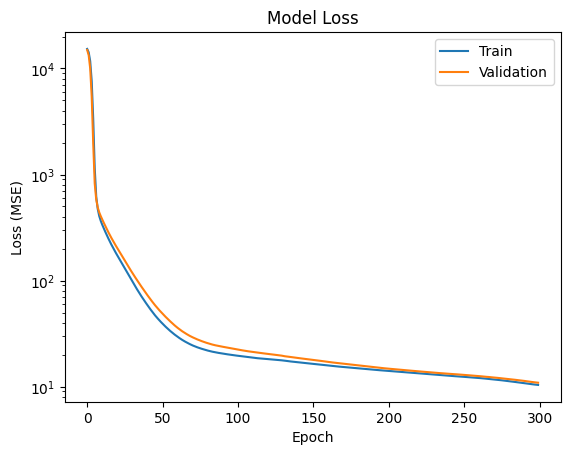

In [13]:
tf.keras.utils.set_random_seed(0)

model = Sequential()
model.add(Dense(64, activation='relu', input_shape=[5]))
model.add(Dense(64, activation='relu'))
model.add(Dense(1))
model.compile(loss='mse', optimizer=optimizers.Adam(learning_rate=0.001))

history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=300, batch_size=32, verbose=0)

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.yscale('log')
plt.title('Model Loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
R^2 on test set: 0.7684065560330537


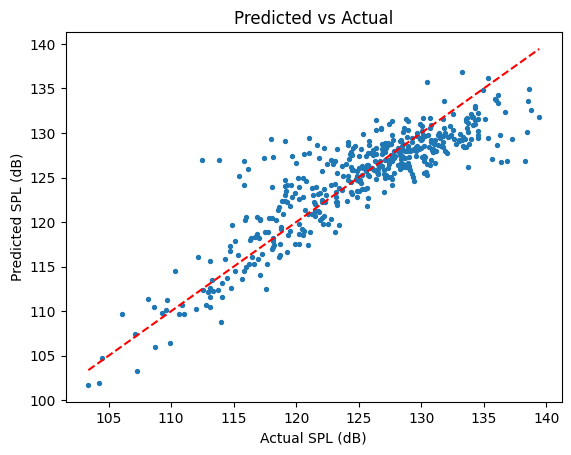

In [14]:
y_pred = model.predict(X_test).ravel()
print('R^2 on test set:', r2_score(y_test, y_pred))

plt.scatter(y_test, y_pred, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual SPL (dB)')
plt.ylabel('Predicted SPL (dB)')
plt.title('Predicted vs Actual')
plt.show()